In [1]:
## Implement the Fitch algorithm BY MYSELF

import networkx as nx
import random 
import matplotlib.pyplot as plt

In [2]:
## TREE BUILDING 
def Build_Graph(states=("A", "C", "G", "T")):
    G= nx.DiGraph()
    G.add_edges_from([(1,2), (1,3), (2,4), (2,5), (3, 6), (3,7)])

    n = int(G.number_of_nodes())

    c = 0
    for node in G.nodes:
        if G.degree(node) == 1:
            G.nodes[node]["state"] = states[c]
            c = c+1
## ---> LIST OF TUPLES (NUMBERS AND STATES AS LABELS)

    layer1, layer2, root_layer = {}, {}, {}

    for node in G.nodes:
        entry = {
            "successor": list(G.successors(node)),
            "state": G.nodes[node].get("state"),
        }
        deg = G.degree(node)
        if deg == 1:
            layer1[node] = entry
        elif deg == 3:
            layer2[node] = entry
        elif deg == 2:          ## BINARY TREE root
            root_layer[node] = entry

    return(layer1, layer2, root_layer, G)


In [3]:
print(Build_Graph())

({4: {'successor': [], 'state': 'A'}, 5: {'successor': [], 'state': 'C'}, 6: {'successor': [], 'state': 'G'}, 7: {'successor': [], 'state': 'T'}}, {2: {'successor': [4, 5], 'state': None}, 3: {'successor': [6, 7], 'state': None}}, {1: {'successor': [2, 3], 'state': None}}, <networkx.classes.digraph.DiGraph object at 0x000002038FFC9A90>)


In [3]:
def Fitch(states: list):
    layer1, layer2, root_layer, G = Build_Graph(states)
    cost = 0
    for layer in (layer2, root_layer):
        for n, attrs in layer.items():
            children_states = []
            for child in attrs["successor"]:
                s = G.nodes[child]["state"]
                if isinstance(s, str):
                    s = {s}                      # leaf string -> set
                children_states.append(s)

            inter = set.intersection(*children_states)
            if inter:
                G.nodes[n]["state"] = inter
                G.nodes[n]["cost"] = 0
            else:
                G.nodes[n]["state"] = set.union(*children_states)
                G.nodes[n]["cost"] = 1
                cost += 1
    root_id = list(root_layer)[0]
    root_state = random.choice(sorted(G.nodes[root_id]["state"]))
    G.nodes[root_id]["state"] = root_state

    for n in layer2:
        candidates = G.nodes[n]["state"]          # still a set here
        if root_state in candidates:
            G.nodes[n]["state"] = root_state
        else:
            G.nodes[n]["state"] = random.choice(sorted(candidates))

    return cost, G
        

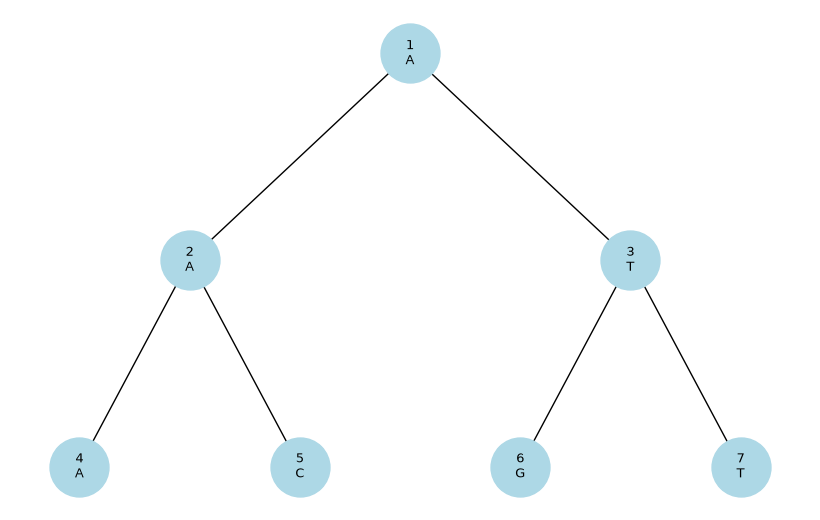

In [5]:
def plot_tree(G, root):
    # depth of each node (root = 0)
    depth = {root: 0}
    for u, v in nx.bfs_edges(G, root):
        depth[v] = depth[u] + 1

    # leaves evenly spaced, in DFS order so edges don't cross
    pos = {}
    leaves = [n for n in nx.dfs_preorder_nodes(G, root) if G.out_degree(n) == 0]
    for i, leaf in enumerate(leaves):
        pos[leaf] = (i, -depth[leaf])

    # parents centered over their children
    def place(n):
        if n in pos:
            return pos[n][0]
        xs = [place(c) for c in G.successors(n)]
        pos[n] = (sum(xs) / len(xs), -depth[n])
        return pos[n][0]
    place(root)

    # labels: node id + state (string for leaves, set for internal nodes)
    labels = {}
    for n, d in G.nodes(data=True):
        s = d.get("state")
        if isinstance(s, (set, frozenset)):
            s = "{" + ",".join(sorted(s)) + "}"
        labels[n] = f"{n}\n{s}"

    plt.figure(figsize=(8, 5))
    nx.draw(G, pos, labels=labels, node_size=1800,
            node_color="lightblue", arrows=False, font_size=9)
    plt.show()

cost, G = Fitch(states=["A", "C", "G", "T"])
plot_tree(G, root=1)    # use your root node id

In [6]:
print(Fitch(states = ["A", "C", "G", "T"]))

(3, <networkx.classes.digraph.DiGraph object at 0x000002039092AAD0>)


In [ ]:
## 1. Where parsimony works. Simulate the evolution of DNA sequences on the four-
## taxon tree ((A, B),(C, D)) under the Jukes–Cantor model. Generate a uniformly random
## sequence at the internal node joining A and B; evolve it along the branch to A, along the
## branch to B, and along the internal branch to the node joining C and D; from there evolve
##it to C and to D. Along each branch, replace each site independently with probability p
## by a uniformly chosen different nucleotide. Use p = 0.05 on all five branches. For sequence
## lengths L ∈ {50, 100, 200, 500, 1000, 2000, 5000} and one hundred replicates each, run Fitch
## on all three unrooted topologies, AB|CD, AC|BD and AD|BC, and record how often the
## minimum-score topology is the true one. Plot the recovery rate against L.

50 0.85
100 0.98
200 1.0
500 1.0
1000 1.0
2000 1.0
5000 1.0


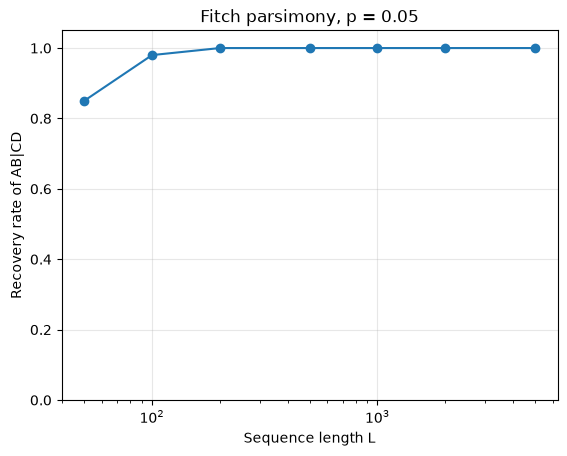

In [5]:
%matplotlib inline  

nuc = ["A", "C", "G", "T"]

def mutate(seq, p):
    new = []
    for x in seq:
        if random.random() < p:
            x = random.choice([y for y in nuc if y != x])   # different nucleotide
        new.append(x)
    return new

def simulate(L, p):
    ab = [random.choice(nuc) for _ in range(L)]   # node joining A and B
    cd = mutate(ab, p)                            # node joining C and D
    return mutate(ab, p), mutate(ab, p), mutate(cd, p), mutate(cd, p)   # A, B, C, D


## PARSIMONY SCORE OF A TOPOLOGY
# Fitch always pairs leaves (0,1) | (2,3), so each topology is just a reordering of A,B,C,D
topologies = {"AB|CD": [0, 1, 2, 3], "AC|BD": [0, 2, 1, 3], "AD|BC": [0, 3, 1, 2]}

cache = {}   # Fitch cost of a site pattern (only 4^4 possible patterns)

def score(seqs, order):
    total = 0
    for site in zip(*seqs):
        leaves = tuple(site[i] for i in order)
        if leaves not in cache:
            cache[leaves] = Fitch(list(leaves))[0]
        total += cache[leaves]
    return total

def true_topology_found(seqs):
    scores = {name: score(seqs, order) for name, order in topologies.items()}
    best = min(scores.values())
    winners = [name for name in scores if scores[name] == best]
    return random.choice(winners) == "AB|CD"      # ties broken at random


## RUN
random.seed(42)
p = 0.05
replicates = 100
lengths = [50, 100, 200, 500, 1000, 2000, 5000]

rates = []
for L in lengths:
    hits = 0
    for r in range(replicates):
        if true_topology_found(simulate(L, p)):
            hits += 1
    rates.append(hits / replicates)
    print(L, hits / replicates)

plt.plot(lengths, rates, "o-")
plt.xscale("log")
plt.ylim(0, 1.05)
plt.xlabel("Sequence length L")
plt.ylabel("Recovery rate of AB|CD")
plt.title("Fitch parsimony, p = 0.05")
plt.grid(alpha=0.3)
plt.show()

In [ ]:
## 2. Where it does not. Repeat item 1 with unequal branches: p = 0.35 on the branches
## leading to A and C, and p = 0.05 on the branches leading to B and D and on the internal
## branch. Plot the recovery rate against L on the same axes as item 1, and record which
## topology wins when the true one does not. Say what happens to the recovery rate as L
## grows, and why a method that becomes more confident in a wrong answer with more data
# is a different kind of failure from one that is merely noisy.

L     equal   unequal   wins when wrong (unequal): AC|BD, AD|BC
50 0.87 0.42 (50, 8)
100 0.99 0.29 (67, 4)
200 1.0 0.34 (66, 0)
500 1.0 0.12 (88, 0)
1000 1.0 0.1 (90, 0)
2000 1.0 0.04 (96, 0)
5000 1.0 0.0 (100, 0)


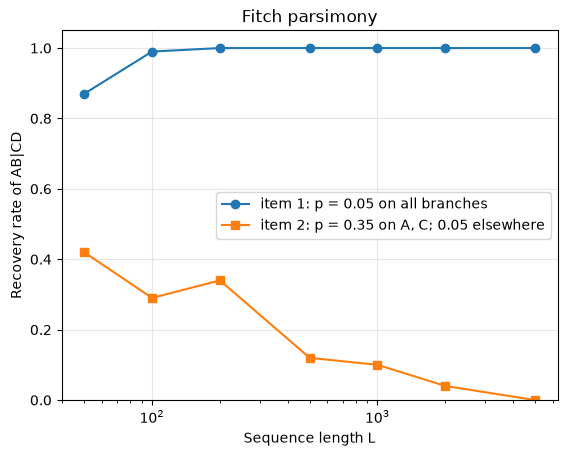

In [6]:
def simulate_branches(L, pA, pB, pC, pD, p_int):
    ab = [random.choice(nuc) for _ in range(L)]   # node joining A and B
    cd = mutate(ab, p_int)                        # node joining C and D
    return mutate(ab, pA), mutate(ab, pB), mutate(cd, pC), mutate(cd, pD)

def winner(seqs):
    scores = {name: score(seqs, order) for name, order in topologies.items()}
    best = min(scores.values())
    winners = [name for name in scores if scores[name] == best]
    return random.choice(winners)                 # ties broken at random

def run(branch_p):
    rates, wrong = [], []
    for L in lengths:
        counts = {"AB|CD": 0, "AC|BD": 0, "AD|BC": 0}
        for r in range(replicates):
            counts[winner(simulate_branches(L, *branch_p))] += 1
        rates.append(counts["AB|CD"] / replicates)
        wrong.append((counts["AC|BD"], counts["AD|BC"]))
    return rates, wrong

random.seed(1)
# order: pA, pB, pC, pD, p_internal
rates_eq, wrong_eq = run([0.05, 0.05, 0.05, 0.05, 0.05])
rates_neq, wrong_neq = run([0.35, 0.05, 0.35, 0.05, 0.05])

print("L     equal   unequal   wins when wrong (unequal): AC|BD, AD|BC")
for i, L in enumerate(lengths):
    print(L, rates_eq[i], rates_neq[i], wrong_neq[i])

plt.plot(lengths, rates_eq, "o-", label="item 1: p = 0.05 on all branches")
plt.plot(lengths, rates_neq, "s-", label="item 2: p = 0.35 on A, C; 0.05 elsewhere")
plt.xscale("log")
plt.ylim(0, 1.05)
plt.xlabel("Sequence length L")
plt.ylabel("Recovery rate of AB|CD")
plt.title("Fitch parsimony")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
## The distance alternative. Take the five sequences from last year’s Homework 3, items 4
## and 5:

## A ACGTACGT
## B ACGTTCGT
## C ATGTTCAT
## D ATGTTGAT
## E ACGTACAT

## Compute the pairwise Hamming distance, p-distance, Jukes–Cantor corrected distance
## and Kimura two-parameter distance, and build the UPGMA tree from each. Then run
## Fitch on the topology ((A, B),(C,(D, E))) and on every other topology you can enumerate
## for five taxa (there are fifteen unrooted ones), and report the most parsimonious. Tabulate
## which clades are stable across the four distance trees and the parsimony tree, and which
## are not. Finally, apply 5% random substitution noise to the sequences, with a fixed seed,
## and repeat; report which clades survive.

In [7]:
import math
from itertools import combinations

## DATA
seqs = {"A": "ACGTACGT", "B": "ACGTTCGT", "C": "ATGTTCAT", "D": "ATGTTGAT", "E": "ACGTACAT"}
taxa = list(seqs)

## DISTANCES
def hamming(s, t):
    return sum(x != y for x, y in zip(s, t))

def p_dist(s, t):
    return hamming(s, t) / len(s)

def jukes_cantor(s, t):
    p = p_dist(s, t)
    if 1 - 4/3 * p <= 0:                         # saturated: distance undefined
        return float("inf")
    return -3/4 * math.log(1 - 4/3 * p)

def kimura(s, t):
    ts = tv = 0
    for x, y in zip(s, t):
        if x != y:
            if (x in "AG") == (y in "AG"):      # purine<->purine or pyrimidine<->pyrimidine
                ts += 1
            else:
                tv += 1
    P, Q = ts / len(s), tv / len(s)
    if 1 - 2*P - Q <= 0 or 1 - 2*Q <= 0:        # saturated: distance undefined
        return float("inf")
    return -1/2 * math.log(1 - 2*P - Q) - 1/4 * math.log(1 - 2*Q)

distances = {"Hamming": hamming, "p-distance": p_dist, "Jukes-Cantor": jukes_cantor, "Kimura 2P": kimura}

def dist_matrix(seqs, f):
    return {(a, b): f(seqs[a], seqs[b]) for a, b in combinations(taxa, 2)}


## UPGMA (trees are nested tuples; with a tie the first minimal pair wins, or the last if last=True)
def upgma(D, last=False):
    clusters = [(t, [t]) for t in taxa]          # (subtree, members)
    while len(clusters) > 1:
        best = None
        for i, j in combinations(range(len(clusters)), 2):
            m1, m2 = clusters[i][1], clusters[j][1]
            d = sum(D[tuple(sorted((a, b)))] for a in m1 for b in m2) / (len(m1) * len(m2))
            if best is None or d < best[0] - 1e-9 or (last and d <= best[0] + 1e-9):
                best = (d, i, j)
        d, i, j = best
        new = ((clusters[i][0], clusters[j][0]), clusters[i][1] + clusters[j][1])
        clusters = [c for k, c in enumerate(clusters) if k not in (i, j)] + [new]
    return clusters[0][0]


## CLADES: nontrivial splits of a 5-taxon tree, each written as its 2-taxon side
def leaves(tree):
    return {tree} if isinstance(tree, str) else leaves(tree[0]) | leaves(tree[1])

def splits(tree):
    out = set()
    def visit(t):
        if isinstance(t, str):
            return
        c = leaves(t)
        if len(c) == 2:
            out.add(frozenset(c))
        elif len(c) == 3:
            out.add(frozenset(set(taxa) - c))
        visit(t[0])
        visit(t[1])
    visit(tree)
    return out

def name(split):
    return "".join(sorted(split)) + "|" + "".join(sorted(set(taxa) - split))


## FITCH for any tree (your Fitch is hard-wired to the 4-taxon tree, same logic here)
def fitch_site(tree, site):
    if isinstance(tree, str):
        return {site[tree]}, 0
    s1, c1 = fitch_site(tree[0], site)
    s2, c2 = fitch_site(tree[1], site)
    inter = s1 & s2
    if inter:
        return inter, c1 + c2
    return s1 | s2, c1 + c2 + 1

def fitch_score(tree, seqs):
    return sum(fitch_site(tree, {t: seqs[t][i] for t in taxa})[1] for i in range(len(seqs["A"])))

## ALL 15 UNROOTED TOPOLOGIES: add C, then D, on every edge; E is attached at the root
def add_leaf(tree, leaf):
    out = [(tree, leaf)]
    if isinstance(tree, tuple):
        for i in range(2):
            for t in add_leaf(tree[i], leaf):
                new = list(tree)
                new[i] = t
                out.append(tuple(new))
    return out

trees = [("A", "B")]
for leaf in "CD":
    trees = [t for tr in trees for t in add_leaf(tr, leaf)]
all_trees = [(t, "E") for t in trees]
print(len(all_trees), "topologies")


## PIPELINE: clades found by each method
def analyze(seqs):
    found = {n: splits(upgma(dist_matrix(seqs, f))) for n, f in distances.items()}
    scores = sorted([(fitch_score(t, seqs), t) for t in all_trees], key=lambda x: x[0])
    best_trees = [t for s, t in scores if s == scores[0][0]]
    found["Parsimony"] = set.intersection(*[splits(t) for t in best_trees])   # clades shared by all best trees
    return found, scores, best_trees


## 1. DISTANCES
for n, f in distances.items():
    print("\n" + n)
    D = dist_matrix(seqs, f)
    for a, b in combinations(taxa, 2):
        print(a, b, round(D[(a, b)], 4))

## 2. TREES
found, scores, best_trees = analyze(seqs)
print()
for n, f in distances.items():
    print("UPGMA", n, upgma(dist_matrix(seqs, f)), "| ties broken the other way:", upgma(dist_matrix(seqs, f), last=True))

print("\nFitch scores, all topologies:")
for s, t in scores:
    print(s, t, [name(x) for x in splits(t)])
given = ((("A", "B"), ("C", ("D", "E"))))
print("\ngiven ((A,B),(C,(D,E))): score", fitch_score(given, seqs))
print("most parsimonious:", scores[0][0], best_trees)

## 3. CLADE TABLE
methods = list(found)
print("\n%-10s" % "clade", *["%-13s" % m for m in methods])
for s in sorted(set.union(*found.values()), key=name):
    print("%-10s" % name(s), *["%-13s" % ("yes" if s in found[m] else "-") for m in methods])

## 4. NOISE (5% per site, fixed seed)
random.seed(42)
noisy = {t: "".join(mutate(seqs[t], 0.05)) for t in taxa}
print("\nnoisy sequences (changed sites):", sum(hamming(seqs[t], noisy[t]) for t in taxa))
for t in taxa:
    print(t, seqs[t], noisy[t])
found_n, scores_n, best_n = analyze(noisy)
print("most parsimonious (noisy):", scores_n[0][0], best_n)
print("\n%-10s" % "clade", *["%-13s" % m for m in methods])
for s in sorted(set.union(*found.values()) | set.union(*found_n.values()), key=name):
    print("%-10s" % name(s), *["%-13s" % (("yes" if s in found[m] else "-") + " -> " + ("yes" if s in found_n[m] else "-")) for m in methods])

## 5. REPEAT THE NOISE 1000 TIMES: how often does each original clade survive?
survive = {m: {s: 0 for s in found[m]} for m in methods}
for r in range(1000):
    noisy = {t: "".join(mutate(seqs[t], 0.05)) for t in taxa}
    f_n = analyze(noisy)[0]
    for m in methods:
        for s in found[m]:
            if s in f_n[m]:
                survive[m][s] += 1
print("\nfraction of 1000 noisy copies in which the original clades survive")
for m in methods:
    print(m, {name(s): c / 1000 for s, c in survive[m].items()})

15 topologies

Hamming
A B 1
A C 3
A D 4
A E 1
B C 2
B D 3
B E 2
C D 1
C E 2
D E 3

p-distance
A B 0.125
A C 0.375
A D 0.5
A E 0.125
B C 0.25
B D 0.375
B E 0.25
C D 0.125
C E 0.25
D E 0.375

Jukes-Cantor
A B 0.1367
A C 0.5199
A D 0.824
A E 0.1367
B C 0.3041
B D 0.5199
B E 0.3041
C D 0.1367
C E 0.3041
D E 0.5199

Kimura 2P
A B 0.1387
A C 0.5623
A D 0.8664
A E 0.1438
B C 0.3466
B D 0.5623
B E 0.3069
C D 0.1387
C E 0.3069
D E 0.5199

UPGMA Hamming (('C', 'D'), ('E', ('A', 'B'))) | ties broken the other way: (('C', 'D'), ('B', ('A', 'E')))
UPGMA p-distance (('C', 'D'), ('E', ('A', 'B'))) | ties broken the other way: (('C', 'D'), ('B', ('A', 'E')))
UPGMA Jukes-Cantor (('C', 'D'), ('E', ('A', 'B'))) | ties broken the other way: (('C', 'D'), ('B', ('A', 'E')))
UPGMA Kimura 2P (('C', 'D'), ('E', ('A', 'B'))) | ties broken the other way: (('C', 'D'), ('E', ('A', 'B')))

Fitch scores, all topologies:
5 ((('A', 'B'), ('C', 'D')), 'E') ['CD|ABE', 'AB|CDE']
5 (('A', ('B', ('C', 'D'))), 'E') ['CD|AB